# Praktikum 1 - Klasterisasi Hierarki Berbasis Kepadatan (HDBSCAN vs DBSCAN)

**Nama:** Mohammad Al Hafis Hidayatulloh  
**NIM:** 254107023005  
**Mata Kuliah:** RTI235004 - Pembelajaran Mesin  
**Dosen Pengampu:** Usman Nurhasan, S.Kom., M.T.

---

Pada praktikum pertama di Jobsheet 5 ini saya mengeksplorasi keunggulan algoritma **HDBSCAN** (*Hierarchical Density-Based Spatial Clustering of Applications with Noise*) dibandingkan **DBSCAN**, khususnya terkait sifat *scale invariance* (ketahanan terhadap perubahan skala data tanpa perlu menyetel ulang parameter radius `eps`) serta kemampuan menangani *multi-scale clustering* (klaster dengan tingkat kepadatan yang berbeda-beda).

### Langkah 1 - Persiapan Lingkungan

Mengimpor modul yang diperlukan (`matplotlib.pyplot`, `numpy`, `DBSCAN`, `make_blobs`, dan `hdbscan`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_blobs
import hdbscan

### Langkah 2 - Definisi Fungsi Visualisasi

Mendefinisikan fungsi `plot()` untuk menampilkan hasil klasterisasi dengan warna berbeda untuk tiap klaster, tanda silang hitam (`x`) untuk titik *noise* (`-1`), serta ukuran titik yang proporsional terhadap nilai probabilitas keanggotaan klaster pada HDBSCAN.

In [2]:
def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}
    
    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]  # warna hitam untuk noise
        class_index = (labels == k).nonzero()[0]
        for ci in class_index:
            ax.plot(
                X[ci, 0],
                X[ci, 1],
                "x" if k == -1 else "o",
                markerfacecolor=tuple(col),
                markeredgecolor="k",
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci],
            )
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = "True" if ground_truth else "Estimated"
    title = f"{preamble} number of clusters: {n_clusters_}"
    if parameters is not None:
        parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
        title += f" | {parameters_str}"
    ax.set_title(title)
    plt.tight_layout()

### Langkah 3 - Membuat Dataset Sintetis

Membuat dataset 750 sampel yang terdiri dari 3 klaster Gaussian dengan simpangan baku berbeda (`cluster_std=[0.4, 0.1, 0.75]`).

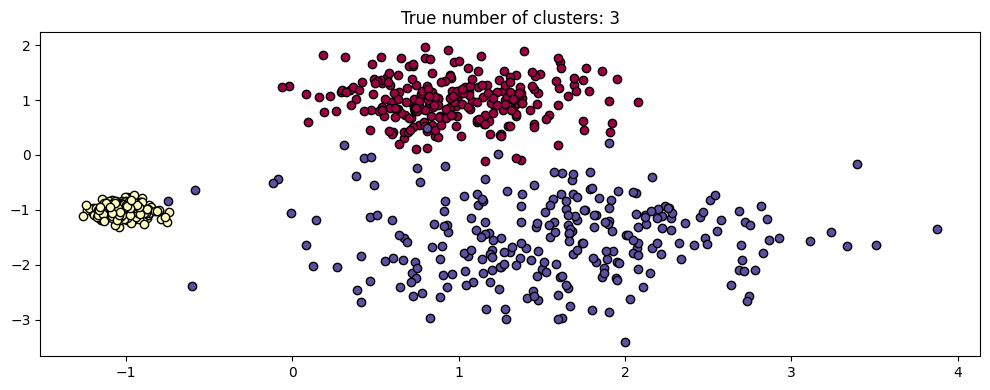

In [3]:
centers = [[1, 1], [-1, -1], [1.5, -1.5]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.4, 0.1, 0.75], random_state=0
)
plot(X, labels=labels_true, ground_truth=True)

### Langkah 4 - Uji Scale Invariance pada DBSCAN

Menjalankan DBSCAN dengan `eps=0.3` tetap pada data `X` yang dikalikan faktor skala `1`, `0.5`, dan `3`.

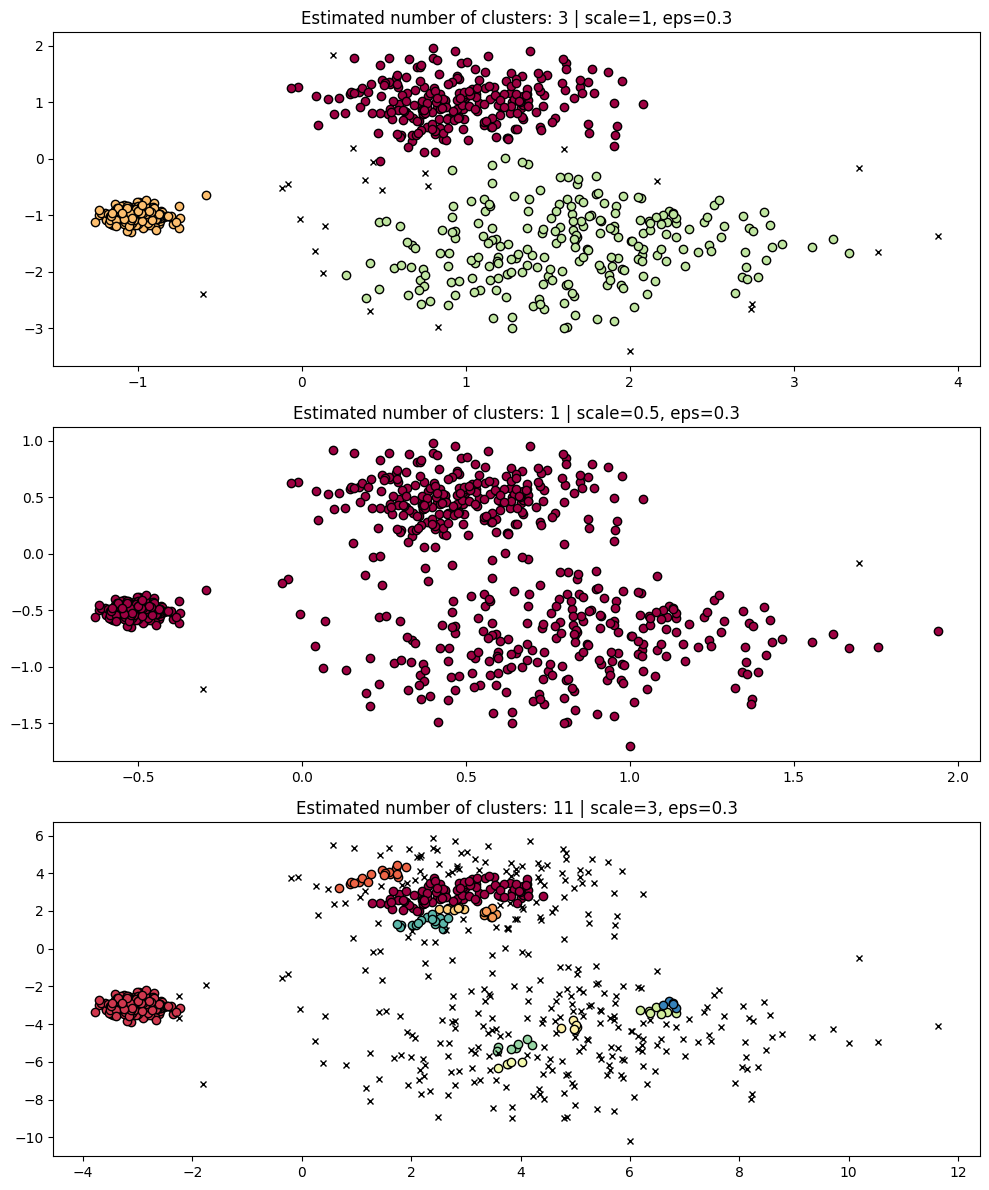

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
dbs = DBSCAN(eps=0.3)
for idx, scale in enumerate([1, 0.5, 3]):
    dbs.fit(X * scale)
    plot(X * scale, dbs.labels_, parameters={"scale": scale, "eps": 0.3}, ax=axes[idx])

Memperbaiki hasil DBSCAN pada `scale=3` dengan menyesuaikan nilai `eps` menjadi `3 * 0.3 = 0.9`:

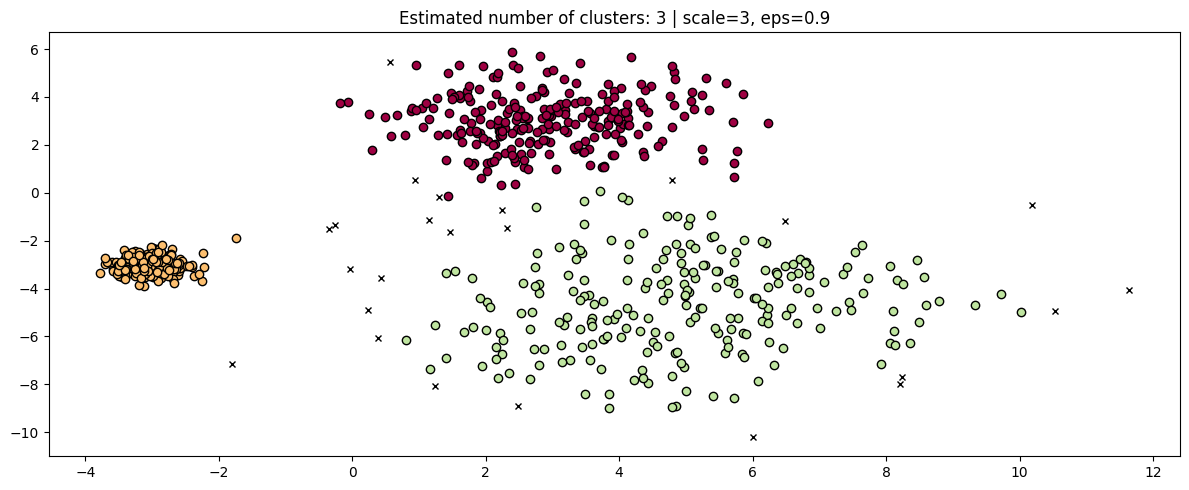

In [5]:
fig, axis = plt.subplots(1, 1, figsize=(12, 5))
dbs = DBSCAN(eps=0.9).fit(3 * X)
plot(3 * X, dbs.labels_, parameters={"scale": 3, "eps": 0.9}, ax=axis)

Terlihat bahwa DBSCAN tidak bersifat *scale-invariant*: ketika skala koordinat data diperkecil (`scale=0.5`), nilai `eps=0.3` menjadi terlalu besar sehingga dua klaster menyatu (hanya ditemukan 2 klaster), sedangkan ketika diperbesar (`scale=3`), `eps=0.3` menjadi terlalu sempit sehingga klaster yang agak renggang pecah menjadi banyak klaster kecil (13 klaster) dan banyak *noise* kecuali nilai `eps` ikut dikalikan 3 menjadi `0.9`.

### Langkah 5 - Bandingkan dengan HDBSCAN (Lebih Robust)

Menjalankan HDBSCAN pada ketiga skala data (`1`, `0.5`, dan `3`) tanpa mengubah parameter apa pun.

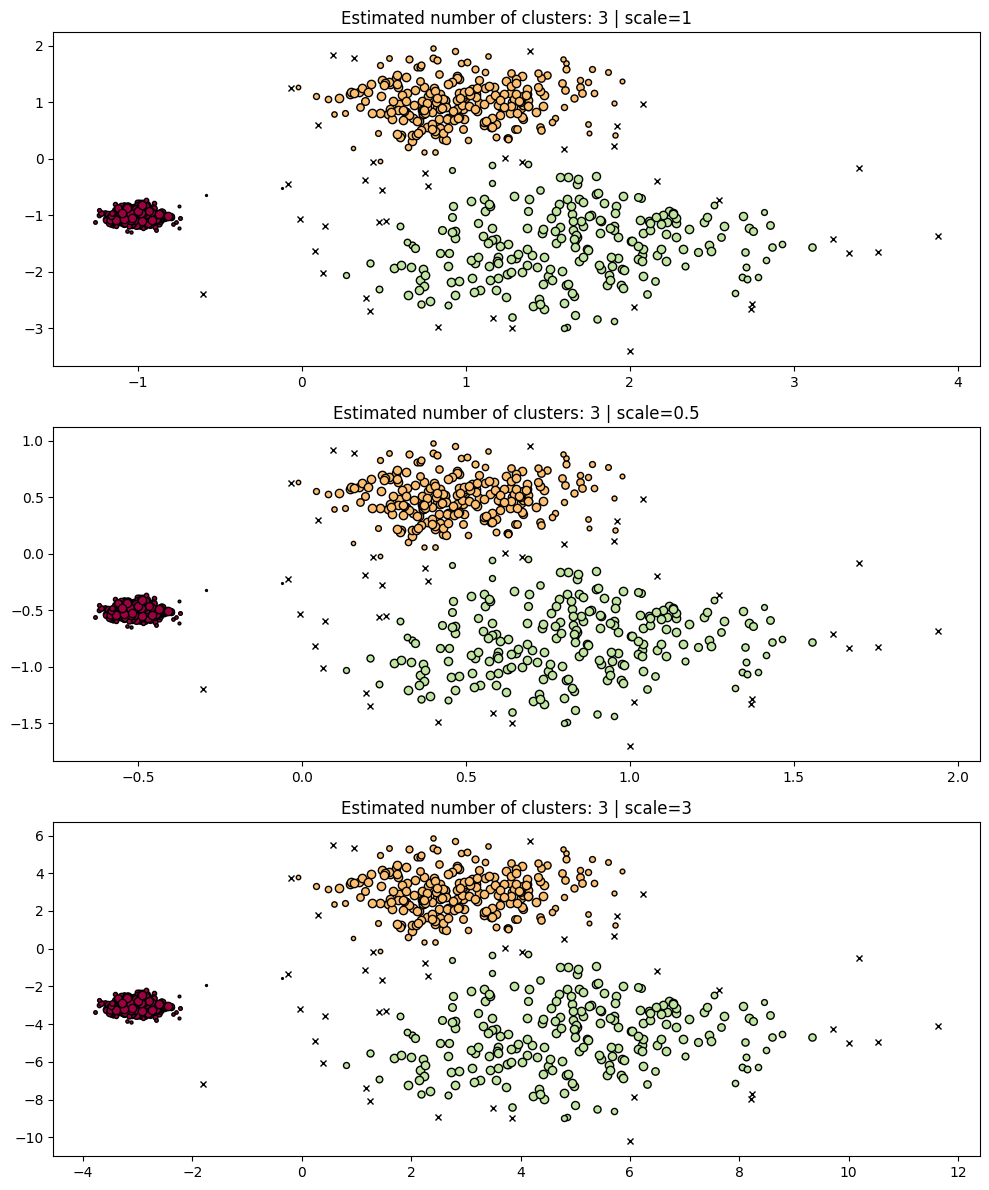

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
hdb = hdbscan.HDBSCAN()
for idx, scale in enumerate([1, 0.5, 3]):
    hdb.fit(X * scale)
    plot(X * scale, hdb.labels_, hdb.probabilities_, ax=axes[idx], parameters={"scale": scale})

Berbeda dengan DBSCAN, HDBSCAN memberikan hasil pengelompokan **3 klaster** yang identik pada `scale=1`, `scale=0.5`, maupun `scale=3` karena HDBSCAN tidak bergantung pada ambang batas jarak global (`eps`), melainkan membangun hierarki dari jarak *mutual reachability* relatif antar tetangga.

### Langkah 6 - Multi-Scale Clustering

Membuat dataset baru yang memiliki 4 klaster dengan perbedaan kepadatan yang jauh (`cluster_std=[0.2, 0.35, 1.35, 1.35]`), lalu membandingkan hasil DBSCAN (`eps=0.7` dan `eps=0.3`) terhadap HDBSCAN.

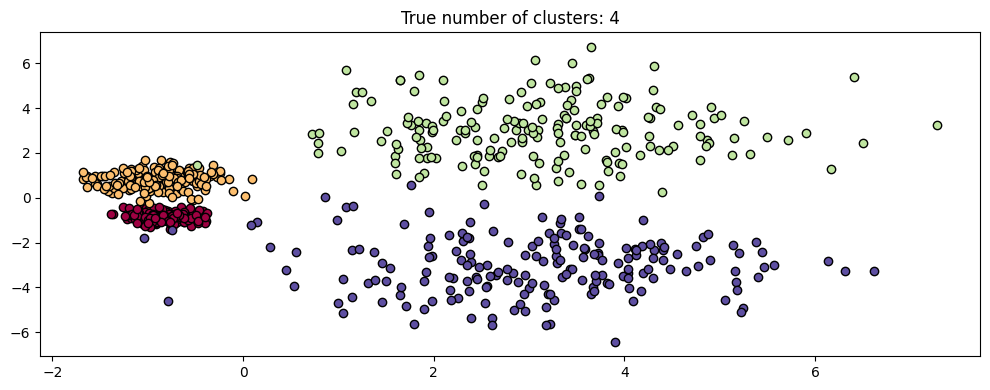

In [7]:
centers = [[-0.85, -0.85], [-0.85, 0.85], [3, 3], [3, -3]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.2, 0.35, 1.35, 1.35], random_state=0
)
plot(X, labels=labels_true, ground_truth=True)

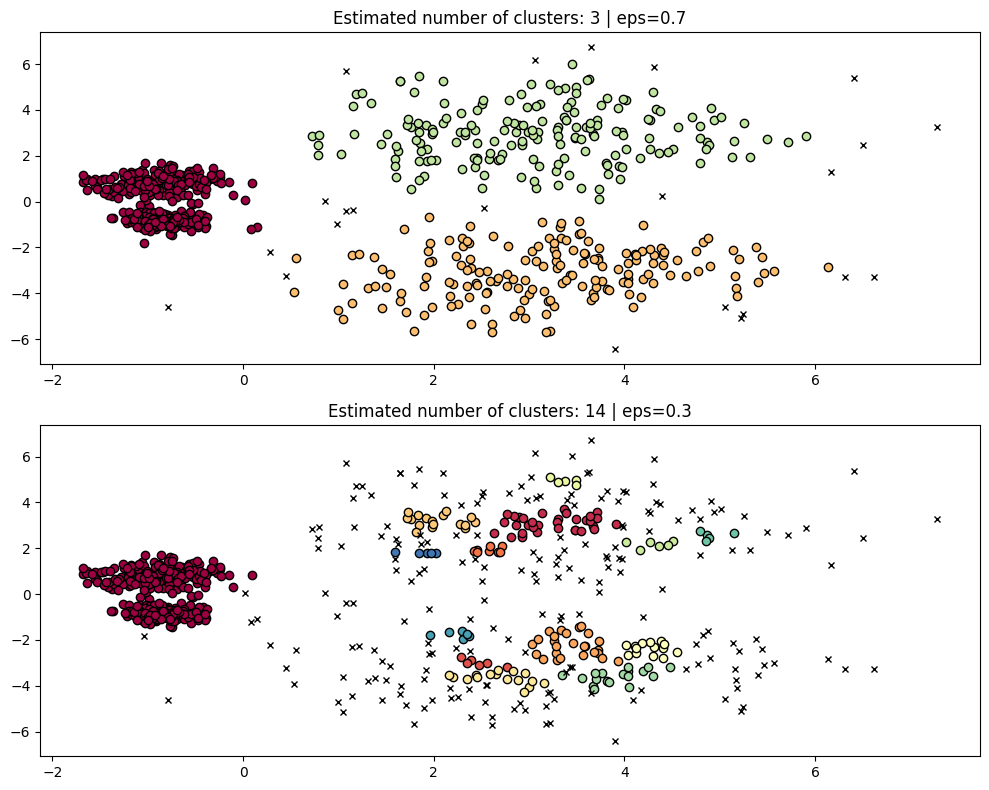

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
params = {"eps": 0.7}
dbs = DBSCAN(**params).fit(X)
plot(X, dbs.labels_, parameters=params, ax=axes[0])

params = {"eps": 0.3}
dbs = DBSCAN(**params).fit(X)
plot(X, dbs.labels_, parameters=params, ax=axes[1])

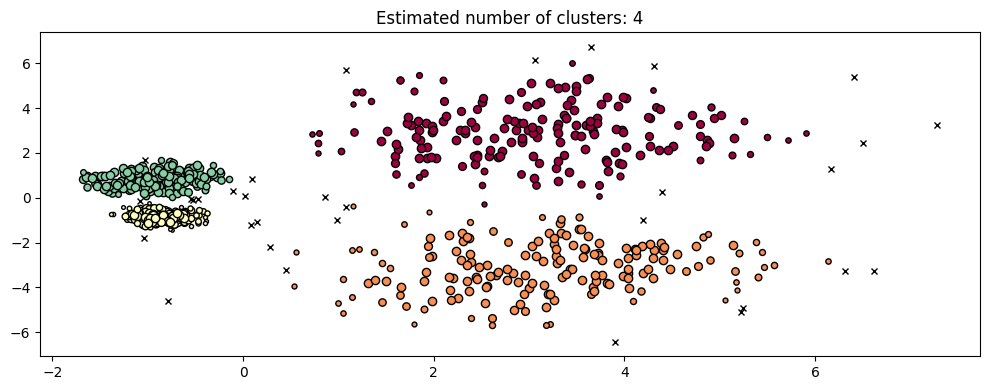

In [9]:
hdb = hdbscan.HDBSCAN().fit(X)
plot(X, hdb.labels_, hdb.probabilities_)

Pada kasus *Multi-Scale Clustering* di atas, DBSCAN mengalami dilema:
- Jika menggunakan `eps=0.7` agar dua klaster renggang di sebelah kanan dapat terdeteksi, maka dua klaster padat di sebelah kiri justru menyatu menjadi satu klaster (total hanya 3 klaster).
- Sebaliknya, jika `eps` diperkecil menjadi `0.3` agar dua klaster padat di kiri terpisah, maka dua klaster renggang di kanan pecah berkeping-keping menjadi banyak klaster kecil (total 9 klaster) dan didominasi *noise*.

Sementara itu, **HDBSCAN** secara otomatis mampu memisahkan kedua klaster padat di kiri sekaligus mempertahankan kedua klaster renggang di kanan sehingga tepat menemukan **4 klaster** sesuai *ground truth*.